In [23]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.distributions import Categorical

In [24]:
def set_seed(seed):  #same seed for all libraries
    np.random.seed(seed)
    torch.manual_seed(seed)

In [25]:
SEED=42
set_seed(SEED)

In [26]:
def make_env(seed, render_mode=None):
    env = gym.make("LunarLander-v3", render_mode=render_mode)

    env.action_space.seed(seed) #fixe le seed pour action aleatoire
    env.observation_space.seed(seed) #fixe le seed pour observation aleatoire
    return env

In [27]:
env = make_env(seed=SEED, render_mode=None)
state, info = env.reset(seed=SEED) #reset environment 
print(state) #x, y vitesse_x, vitesse_y, angle, vitesse_angulaire, contact_gauche, contact_droit

[ 0.00229702  1.4181306   0.23264714  0.32046658 -0.00265488 -0.05269808
  0.          0.        ]


In [28]:
def get_end_reason(
        final_state,
        final_reward,
        terminated,
        truncated):
    if truncated:
        return "truncated" #max steps reached
    if not terminated:
        return "unknown" #unexpected termination
    if final_reward > 0:
        return "at rest" 
    if abs(final_state[0]) >= 1.0: #gauche ou droite
        return "out of bounds"
    return "crashed"

In [29]:
def run_random_agent(env, num_episodes, base_seed): #parameters 
    episode_rewards = [] #la recompense totale pour chaque épisode
    episode_lenghts = [] #le nombre de pas/etapes pour chaque épisode
    end_reasons = [] #la raison

    env.action_space.seed(base_seed)

    for episode in range(num_episodes):
        state, info = env.reset(seed=base_seed + episode) #on utilise un seed different pour chaque episode
        terminated = False
        truncated = False
        total_reward = 0
        episode_steps = 0

        while not (terminated or truncated):
            action = env.action_space.sample() #0 ne rien faire, 1 moteur gauche, 2 moteur principal, 3 moteur droit

            next_state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            episode_steps += 1
            state = next_state


        end_reason = get_end_reason(
            final_state = state,
            final_reward = reward, 
            terminated = terminated,
            truncated = truncated
        )
        #enregistre les res dans les listes
        episode_rewards.append(total_reward)
        episode_lenghts.append(episode_steps)
        end_reasons.append(end_reason)
        
    #retourne les res sous forme de dictionnaire
    return {
        "rewards": np.array(episode_rewards),
        "lengths": np.array(episode_lenghts),
        "end_reasons": end_reasons
    }


In [30]:
AGENT_EPISODES = 100

baseline_results = run_random_agent(env, num_episodes=AGENT_EPISODES, base_seed=SEED)

In [31]:
assert len(baseline_results["rewards"]) == AGENT_EPISODES
assert len(baseline_results["lengths"]) == AGENT_EPISODES
assert len(baseline_results["end_reasons"]) == AGENT_EPISODES

#verifie que toutes les recompenses sont valides (pas de NaN ou infini)
assert np.all(
    np.isfinite(baseline_results["rewards"])  
)

assert np.all(
    baseline_results["lengths"] > 0
)

print("Baseline data is valid")

Baseline data is valid


In [32]:
baseline_rewards = baseline_results["rewards"]
baseline_lengths = baseline_results["lengths"]

print(
    f"Episodes: {AGENT_EPISODES}"
)

print(
    f"Mean reward: "
    f"{baseline_rewards.mean():.2f}"
)

print(
    f"Reward standard deviation: "
    f"{baseline_rewards.std():.2f}"
)

print(
    f"Minimum reward: "
    f"{baseline_rewards.min():.2f}"
)

print(
    f"Maximum reward: "
    f"{baseline_rewards.max():.2f}"
)

print(
    f"Mean episode length: "
    f"{baseline_lengths.mean():.2f}"
)

Episodes: 100
Mean reward: -174.82
Reward standard deviation: 102.74
Minimum reward: -461.57
Maximum reward: 22.31
Mean episode length: 89.54


In [33]:
from collections import Counter

reason_counts = Counter(
    baseline_results["end_reasons"]
)

print("End reasons:")

for reason, count in reason_counts.items():
    print(f"{reason}: {count}")

End reasons:
crashed: 91
out of bounds: 9


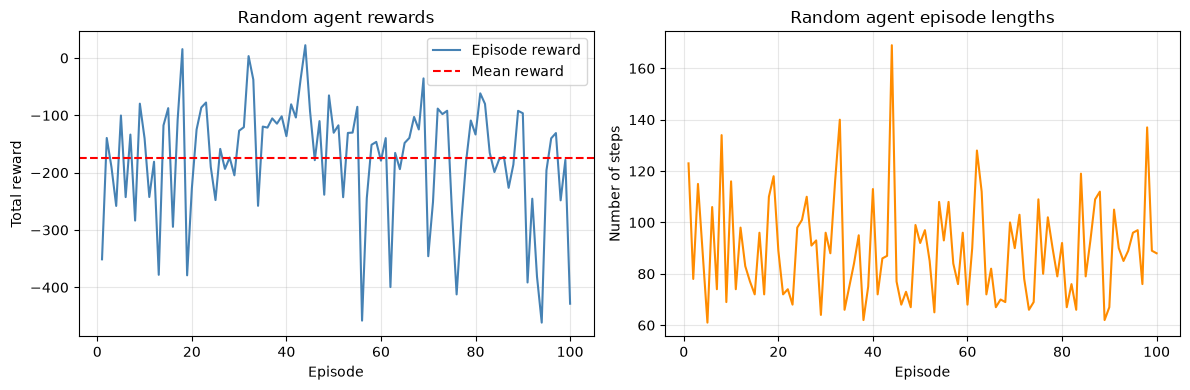

In [34]:
episodes = np.arange(1, AGENT_EPISODES + 1)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
)

axes[0].plot(
    episodes,
    baseline_rewards,
    color="steelblue",
    label="Episode reward",
)

axes[0].axhline(
    baseline_rewards.mean(),
    color="red",
    linestyle="--",
    label="Mean reward",
)

axes[0].set_title("Random agent rewards")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Total reward")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    episodes,
    baseline_lengths,
    color="darkorange",
)

axes[1].set_title("Random agent episode lengths")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Number of steps")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
state_size = env.observation_space.shape[0]
action_size = env.action_space.n

print("State size:", state_size) 
print("Action size:", action_size)

State size: 8
Action size: 4


In [ ]:
class ActorCritic(nn.Module):
    def __init__(self, state_size, action_size, hidden_size=64):
        super().__init__()
        self.actor = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, action_size),
        )
        self.critic = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, 1),
        )

    def forward(self,state):
        action_logits = self.actor(state)
        state_value = self.critic(state).squeeze(-1)  # Remove the last dimension
        return action_logits, state_value

    def get_action_and_value(
        self, state, action=None
    ):
        action_logits, state_value = self(state)

        distribution = Categorical(logits=action_logits)

        if action is None:
            action = distribution.sample()
        log_probability = distribution.log_prob(action)
        entropy = distribution.entropy()

        return (
            action, log_probability, entropy, state_value)
    

In [37]:
device = torch.device("cpu")

set_seed(SEED)

model = ActorCritic(
    state_size=state_size,
    action_size=action_size,
    hidden_size=64,
).to(device)

print(model)

ActorCritic(
  (actor): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
  (critic): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
